# Real Estate & Housing Market Intelligence System
### End-to-End Housing Market Analysis, Price Valuation, Machine Learning & Database Intelligence

**Tools & Ecosystem:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn, XGBoost, MySQL (`realestate_db`), Power BI, JupyterLab  
**Dataset:** Kaggle House Prices: Advanced Regression Techniques (1,460 houses, 79+ physical, spatial, and amenity attributes)  
**System Architecture:** Data Ingestion -> Cleaning & IQR Outlier Filtering -> Feature Engineering -> Statistical EDA -> Supervised ML Benchmarking -> MySQL Database Warehouse -> Power BI BI Intelligence


---
## STEP 1 — DATA COLLECTION AND LOADING
In this initial step, we load the raw Kaggle housing market dataset (`train.csv`), inspect its structural dimensions, examine feature data types, scan for missing values across all columns, identify the top 20 most incomplete features, and compute baseline summary statistics.


In [1]:
# Import standard data manipulation and analysis libraries
import os
import sys
import pandas as pd
import numpy as np

# Set display options to inspect all columns cleanly
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

print("=" * 70)
print("STEP 1: DATA COLLECTION AND LOADING IN PROGRESS...")
print("=" * 70)

try:
    # Locate dataset path (checking current directory or user home)
    dataset_path = 'train.csv'
    if not os.path.exists(dataset_path):
        dataset_path = r'C:\Users\HP\train.csv'
    
    # Read the dataset into a pandas DataFrame
    df = pd.read_csv(dataset_path)
    print(f"\n[SUCCESS] Loaded dataset successfully from: {dataset_path}")
    
    # Print shape: number of rows (houses) and columns (features)
    print(f"[INFO] Dataset Dimensions: {df.shape[0]} rows (properties) and {df.shape[1]} columns (features)\n")
    
    # Print column names
    print("--- DATASET COLUMNS ---")
    print(df.columns.tolist())
    
    # Display the first 5 records of the dataset
    print("\n--- FIRST 5 ROWS (HEAD) ---")
    print(df.head())
    
    # Display data types of each column
    print("\n--- COLUMN DATA TYPES ---")
    print(df.dtypes.value_counts())
    print("\nDetailed Dtypes Sample:")
    print(df.dtypes.head(20))
    
    # Check total missing values across the dataset
    total_missing = df.isnull().sum().sum()
    print(f"\n[INFO] Total Missing Data Points across entire dataset: {total_missing}")
    
    # Calculate missing values count and percentage per column
    missing_counts = df.isnull().sum()
    missing_pct = (missing_counts / len(df)) * 100
    missing_summary = pd.DataFrame({'Missing_Count': missing_counts, 'Missing_Percentage': missing_pct})
    
    # Filter and display the top 20 columns with the highest missing values
    top_20_missing = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False).head(20)
    print("\n--- TOP 20 COLUMNS WITH MOST MISSING VALUES ---")
    print(top_20_missing.to_string())
    
    # Print comprehensive descriptive statistics for numerical columns
    print("\n--- SUMMARY STATISTICS (DESCRIBE) ---")
    print(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])
    
except Exception as error:
    # Gracefully catch and display any file loading errors
    print(f"[ERROR] Failed during Step 1 Data Collection: {error}")


STEP 1: DATA COLLECTION AND LOADING IN PROGRESS...

[SUCCESS] Loaded dataset successfully from: train.csv
[INFO] Dataset Dimensions: 1460 rows (properties) and 81 columns (features)

--- DATASET COLUMNS ---
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'G

---
## STEP 2 — DATA CLEANING & OUTLIER MITIGATION
Data cleanliness is essential for robust predictive modeling. In this step:
1. Columns with **greater than 50% missing values** are dropped.
2. Missing values in **numerical features** are imputed with the column **median** (robust against skewness).
3. Missing values in **categorical features** are imputed with the column **mode** (most frequent class).
4. Extreme price outliers in `SalePrice` are pruned using the **Interquartile Range (IQR)** method (Q1 - 1.5 * IQR to Q3 + 1.5 * IQR).
5. A comprehensive before-and-after cleaning audit is printed.


In [2]:
print("=" * 70)
print("STEP 2: DATA CLEANING & OUTLIER MITIGATION IN PROGRESS...")
print("=" * 70)

try:
    # Record original shape prior to cleaning operations
    original_shape = df.shape
    print(f"[INFO] Shape before cleaning: {original_shape}")
    
    # 1. Identify columns having more than 50% missing values
    missing_threshold = 0.50
    missing_fraction = df.isnull().mean()
    cols_to_drop = missing_fraction[missing_fraction > missing_threshold].index.tolist()
    print(f"[INFO] Columns exceeding 50% missing threshold to drop: {cols_to_drop}")
    
    # Drop identified heavily missing columns from the dataframe
    df_clean = df.drop(columns=cols_to_drop).copy()
    
    # 2. Segregate numeric and categorical columns for type-specific imputation
    numerical_columns = df_clean.select_dtypes(include=[np.number]).columns.tolist()
    categorical_columns = df_clean.select_dtypes(include=['object', 'string']).columns.tolist()
    
    # Impute missing numerical columns with their respective median
    imputed_num_cols = []
    for col in numerical_columns:
        if df_clean[col].isnull().sum() > 0:
            median_val = df_clean[col].median()
            df_clean[col] = df_clean[col].fillna(median_val)
            imputed_num_cols.append(col)
    print(f"[INFO] Numerical columns imputed with median ({len(imputed_num_cols)}): {imputed_num_cols}")
    
    # Impute missing categorical columns with their respective mode
    imputed_cat_cols = []
    for col in categorical_columns:
        if df_clean[col].isnull().sum() > 0:
            mode_val = df_clean[col].mode()[0]
            df_clean[col] = df_clean[col].fillna(mode_val)
            imputed_cat_cols.append(col)
    print(f"[INFO] Categorical columns imputed with mode ({len(imputed_cat_cols)}): {imputed_cat_cols}")
    
    # Confirm no null values remain in the cleaned dataframe
    remaining_nulls = df_clean.isnull().sum().sum()
    print(f"[VERIFY] Remaining null values after imputation: {remaining_nulls}")
    
    # 3. Detect and remove extreme outliers in SalePrice using the IQR method
    Q1 = df_clean['SalePrice'].quantile(0.25)
    Q3 = df_clean['SalePrice'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    print(f"\n--- IQR OUTLIER DETECTION BOUNDS FOR SalePrice ---")
    print(f"Q1 (25th Percentile): ${Q1:,.2f}")
    print(f"Q3 (75th Percentile): ${Q3:,.2f}")
    print(f"IQR: ${IQR:,.2f}")
    print(f"Lower Bound (Q1 - 1.5*IQR): ${lower_bound:,.2f}")
    print(f"Upper Bound (Q3 + 1.5*IQR): ${upper_bound:,.2f}")
    
    # Count properties outside the calculated statistical bounds
    outliers_mask = (df_clean['SalePrice'] < lower_bound) | (df_clean['SalePrice'] > upper_bound)
    outlier_count = outliers_mask.sum()
    print(f"[INFO] Total SalePrice outliers detected and removed: {outlier_count}")
    
    # Filter dataset to retain non-outlier residential sales
    df_clean = df_clean[~outliers_mask].reset_index(drop=True)
    cleaned_shape = df_clean.shape
    
    # 4. Print comprehensive cleaning summary
    print(f"\n{'=' * 70}")
    print("DATA CLEANING SUMMARY")
    print(f"{'=' * 70}")
    print(f"Original Dataset Shape:       {original_shape[0]} rows, {original_shape[1]} columns")
    print(f"Dropped High-Missing Columns: {len(cols_to_drop)} columns dropped: {cols_to_drop}")
    print(f"Outlier Houses Pruned:        {outlier_count} records")
    print(f"Final Cleaned Dataset Shape:  {cleaned_shape[0]} rows, {cleaned_shape[1]} columns")
    print(f"{'=' * 70}\n")

except Exception as error:
    # Gracefully catch and display any cleaning step errors
    print(f"[ERROR] Failed during Step 2 Data Cleaning: {error}")


STEP 2: DATA CLEANING & OUTLIER MITIGATION IN PROGRESS...
[INFO] Shape before cleaning: (1460, 81)
[INFO] Columns exceeding 50% missing threshold to drop: ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']
[INFO] Numerical columns imputed with median (3): ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']
[INFO] Categorical columns imputed with mode (11): ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Electrical', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
[VERIFY] Remaining null values after imputation: 0

--- IQR OUTLIER DETECTION BOUNDS FOR SalePrice ---
Q1 (25th Percentile): $129,975.00
Q3 (75th Percentile): $214,000.00
IQR: $84,025.00
Lower Bound (Q1 - 1.5*IQR): $3,937.50
Upper Bound (Q3 + 1.5*IQR): $340,037.50
[INFO] Total SalePrice outliers detected and removed: 61

DATA CLEANING SUMMARY
Original Dataset Shape:       1460 rows, 81 columns
Dropped High-Missing Columns: 5 columns dropped: ['Alley', 'MasVnrType', 'PoolQC', '

---
## STEP 3 — FEATURE ENGINEERING
Domain-specific feature engineering unlocks substantial predictive performance. We generate 12 new real estate indicators:
- **`House_Age`**: 2025 - YearBuilt
- **`Remodel_Age`**: 2025 - YearRemodAdd
- **`Total_SF`**: TotalBsmtSF + 1stFlrSF + 2ndFlrSF (Total usable square footage)
- **`Total_Bathrooms`**: FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath
- **`Has_Pool`**: Binary indicator (1 if PoolArea > 0, else 0)
- **`Has_Garage`**: Binary indicator (1 if GarageArea > 0, else 0)
- **`Has_Basement`**: Binary indicator (1 if TotalBsmtSF > 0, else 0)
- **`Has_Fireplace`**: Binary indicator (1 if Fireplaces > 0, else 0)
- **`Price_Per_SF`**: SalePrice / Total_SF
- **`Quality_Score`**: OverallQual * OverallCond (Compound quality-condition index)
- **`Is_New`**: Binary indicator (1 if House_Age < 5, else 0)
- **`Season_Sold`**: Calendar mapping of `MoSold` into Spring, Summer, Fall, Winter


In [3]:
print("=" * 70)
print("STEP 3: FEATURE ENGINEERING IN PROGRESS...")
print("=" * 70)

try:
    # Reference year for age computation
    current_year = 2025
    
    # 1. House_Age: 2025 minus YearBuilt
    df_clean['House_Age'] = current_year - df_clean['YearBuilt']
    
    # 2. Remodel_Age: 2025 minus YearRemodAdd
    df_clean['Remodel_Age'] = current_year - df_clean['YearRemodAdd']
    
    # 3. Total_SF: TotalBsmtSF + 1stFlrSF + 2ndFlrSF
    df_clean['Total_SF'] = df_clean['TotalBsmtSF'] + df_clean['1stFlrSF'] + df_clean['2ndFlrSF']
    
    # 4. Total_Bathrooms: FullBath + 0.5*HalfBath + BsmtFullBath + 0.5*BsmtHalfBath
    df_clean['Total_Bathrooms'] = (
        df_clean['FullBath'] + 
        0.5 * df_clean['HalfBath'] + 
        df_clean['BsmtFullBath'] + 
        0.5 * df_clean['BsmtHalfBath']
    )
    
    # 5. Has_Pool: 1 if PoolArea > 0 else 0
    df_clean['Has_Pool'] = (df_clean['PoolArea'] > 0).astype(int)
    
    # 6. Has_Garage: 1 if GarageArea > 0 else 0
    df_clean['Has_Garage'] = (df_clean['GarageArea'] > 0).astype(int)
    
    # 7. Has_Basement: 1 if TotalBsmtSF > 0 else 0
    df_clean['Has_Basement'] = (df_clean['TotalBsmtSF'] > 0).astype(int)
    
    # 8. Has_Fireplace: 1 if Fireplaces > 0 else 0
    df_clean['Has_Fireplace'] = (df_clean['Fireplaces'] > 0).astype(int)
    
    # 9. Price_Per_SF: SalePrice / Total_SF (rounded to 2 decimal places)
    df_clean['Price_Per_SF'] = np.round(df_clean['SalePrice'] / df_clean['Total_SF'], 2)
    
    # 10. Quality_Score: OverallQual * OverallCond
    df_clean['Quality_Score'] = df_clean['OverallQual'] * df_clean['OverallCond']
    
    # 11. Is_New: 1 if House_Age < 5 else 0
    df_clean['Is_New'] = (df_clean['House_Age'] < 5).astype(int)
    
    # 12. Season_Sold: mapping MoSold to Spring, Summer, Fall, Winter
    season_dictionary = {
        12: 'Winter', 1: 'Winter', 2: 'Winter',
        3: 'Spring', 4: 'Spring', 5: 'Spring',
        6: 'Summer', 7: 'Summer', 8: 'Summer',
        9: 'Fall', 10: 'Fall', 11: 'Fall'
    }
    df_clean['Season_Sold'] = df_clean['MoSold'].map(season_dictionary)
    
    # Define engineered column list for verification
    engineered_columns = [
        'House_Age', 'Remodel_Age', 'Total_SF', 'Total_Bathrooms',
        'Has_Pool', 'Has_Garage', 'Has_Basement', 'Has_Fireplace',
        'Price_Per_SF', 'Quality_Score', 'Is_New', 'Season_Sold'
    ]
    
    print("[SUCCESS] Successfully engineered 12 domain features!")
    print(f"[INFO] New Dataset Shape with engineered features: {df_clean.shape}")
    print("\n--- SAMPLE OF ENGINEERED FEATURES ---")
    print(df_clean[['Id', 'SalePrice'] + engineered_columns].head(10).to_string())

except Exception as error:
    # Gracefully catch and display any feature engineering errors
    print(f"[ERROR] Failed during Step 3 Feature Engineering: {error}")


STEP 3: FEATURE ENGINEERING IN PROGRESS...
[SUCCESS] Successfully engineered 12 domain features!
[INFO] New Dataset Shape with engineered features: (1399, 88)

--- SAMPLE OF ENGINEERED FEATURES ---
   Id  SalePrice  House_Age  Remodel_Age  Total_SF  Total_Bathrooms  Has_Pool  Has_Garage  Has_Basement  Has_Fireplace  Price_Per_SF  Quality_Score  Is_New Season_Sold
0   1     208500         22           22      2566              3.5         0           1             1              0         81.25             35       0      Winter
1   2     181500         49           49      2524              2.5         0           1             1              1         71.91             48       0      Spring
2   3     223500         24           23      2706              3.5         0           1             1              1         82.59             35       0        Fall
3   4     140000        110           55      2473              2.0         0           1             1              1         56.

---
## STEP 4 — EXPLORATORY DATA ANALYSIS (EDA)
In this step, we execute in-depth visual analyses addressing 10 critical market questions:
1. *What is the distribution of house prices?*
2. *Which neighborhoods have the highest prices?*
3. *How does house size affect price?*
4. *How does house quality affect price?*
5. *Which features correlate most with price?*
6. *How does house age affect price?*
7. *Which sale conditions fetch highest prices?*
8. *How does garage size affect price?*
9. *What is the price trend by year sold?*
10. *Which season has the most sales?*


STEP 4: GENERATING 10 PROFESSIONAL EDA VISUALIZATIONS...
<string>:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
<string>:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
<s

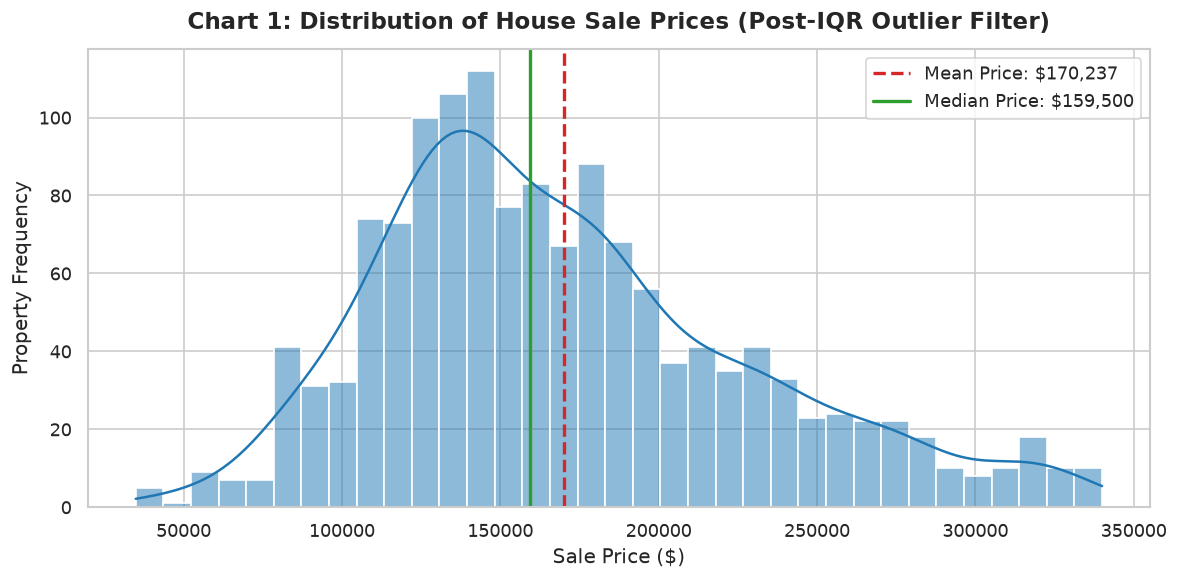

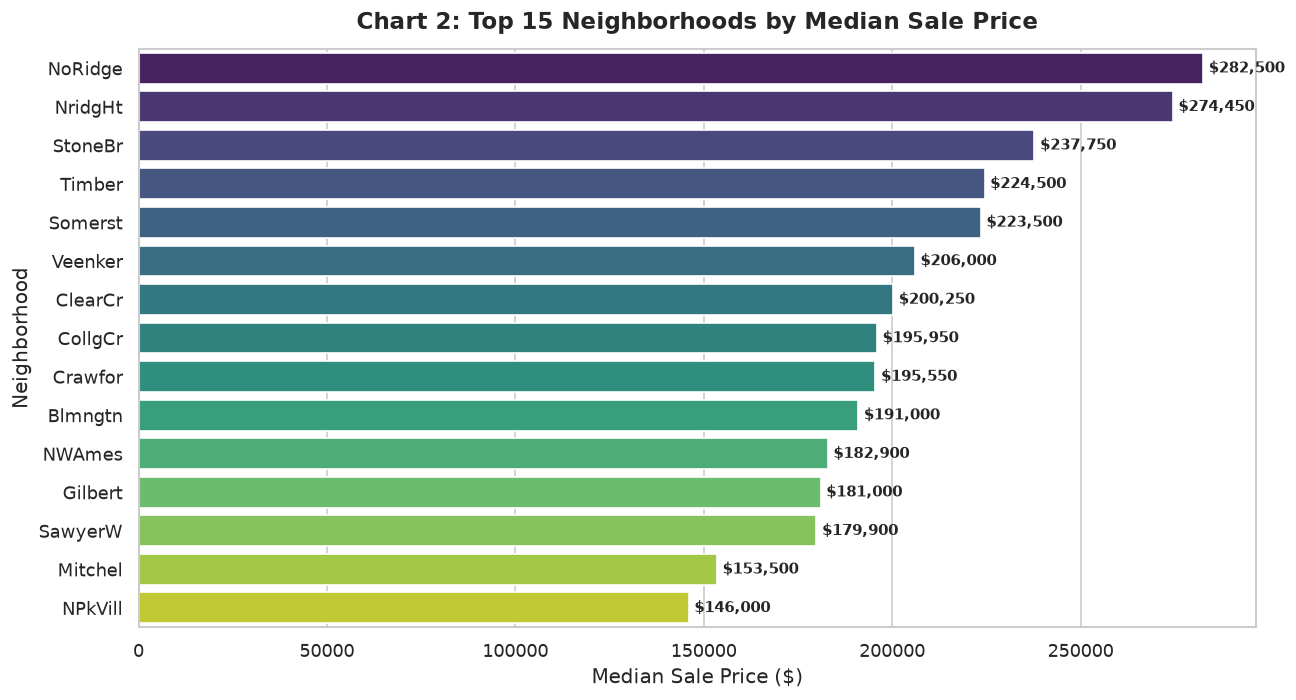

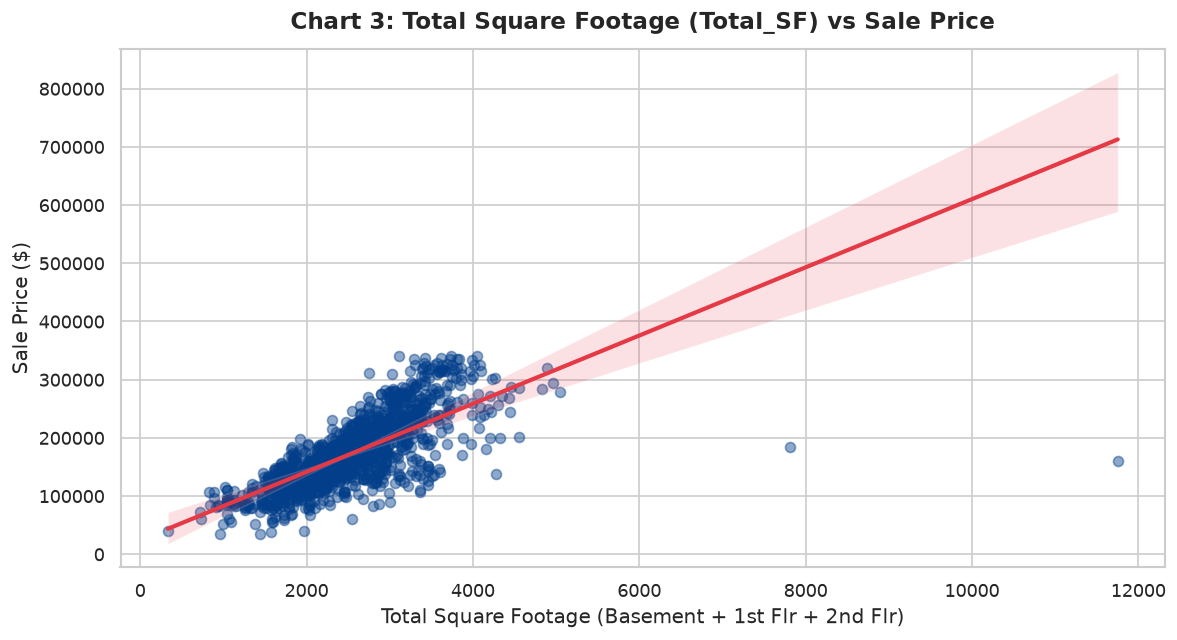

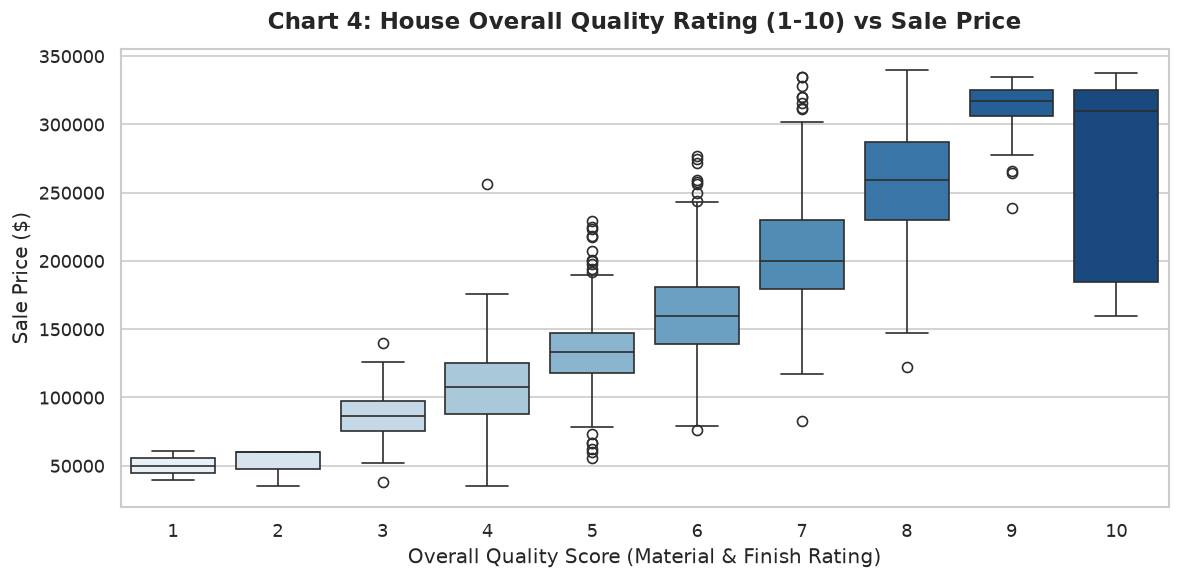

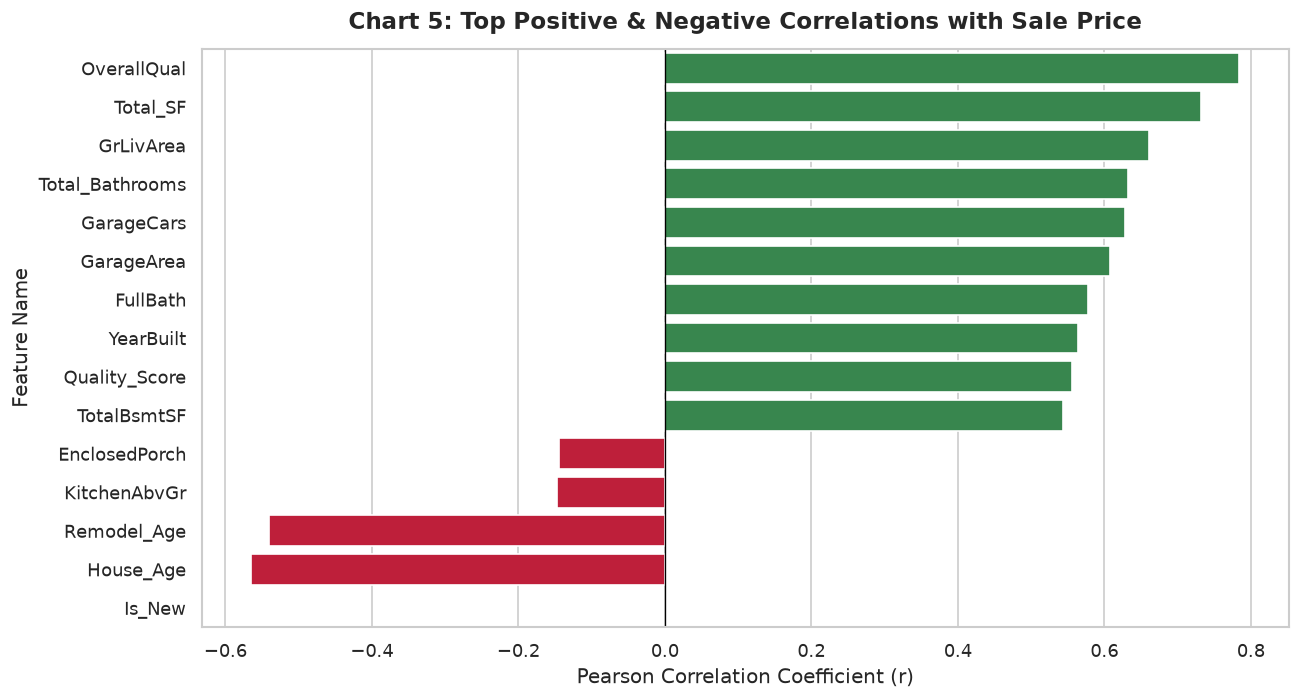

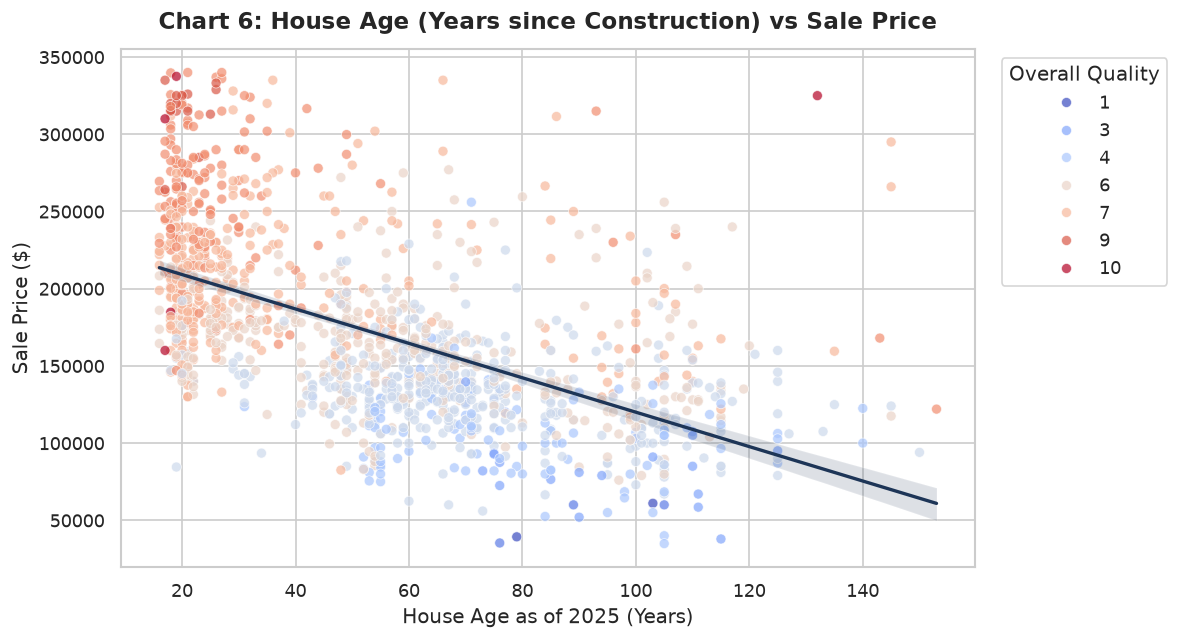

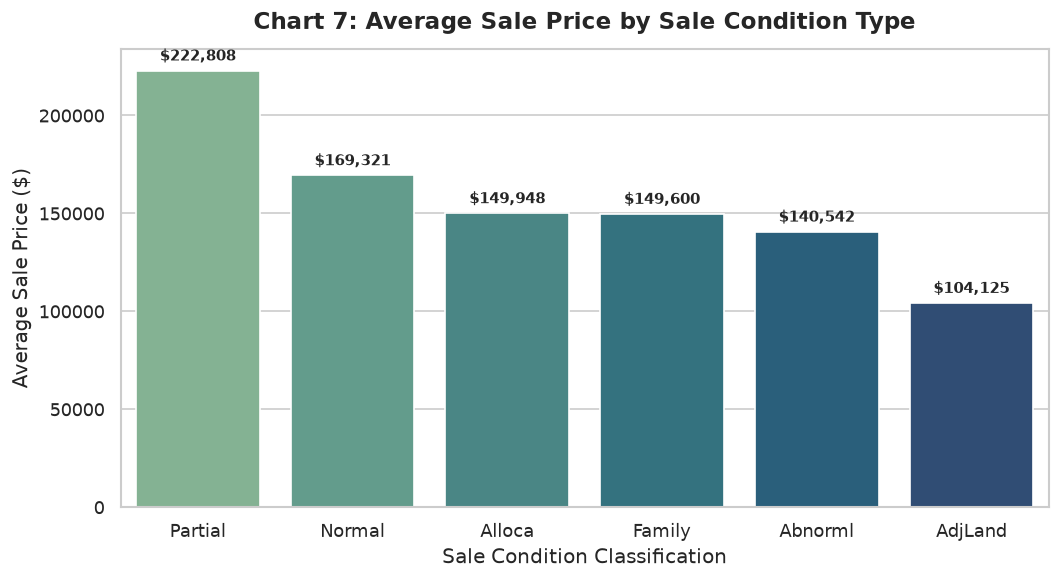

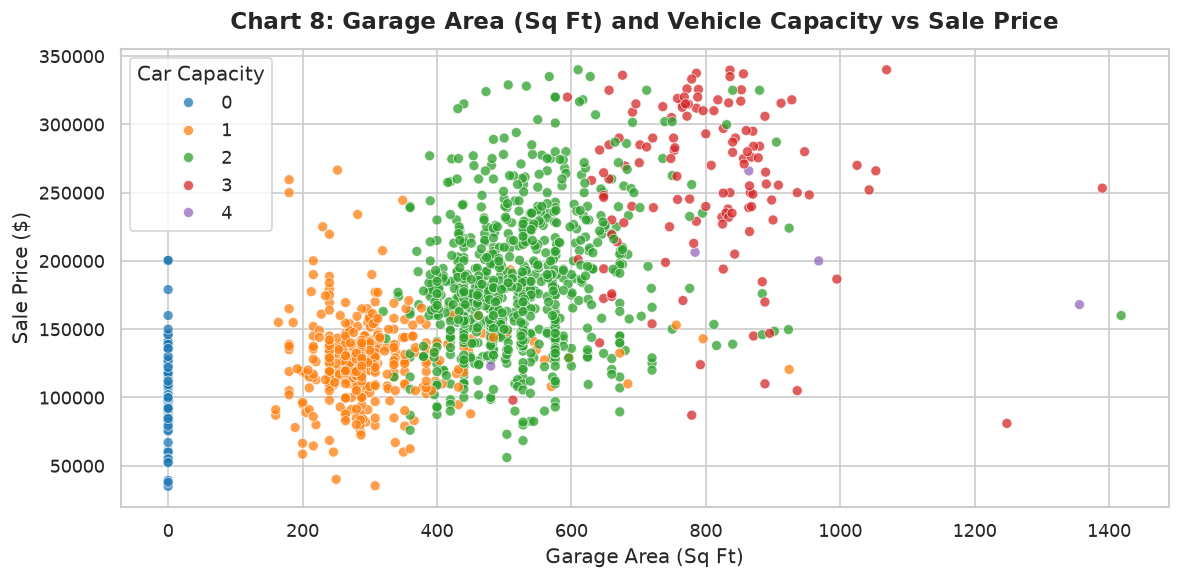

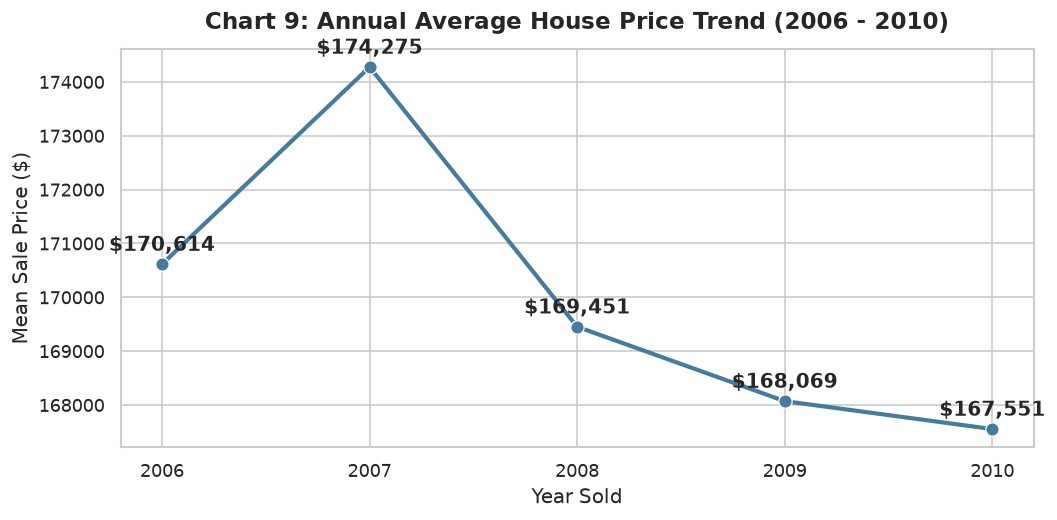

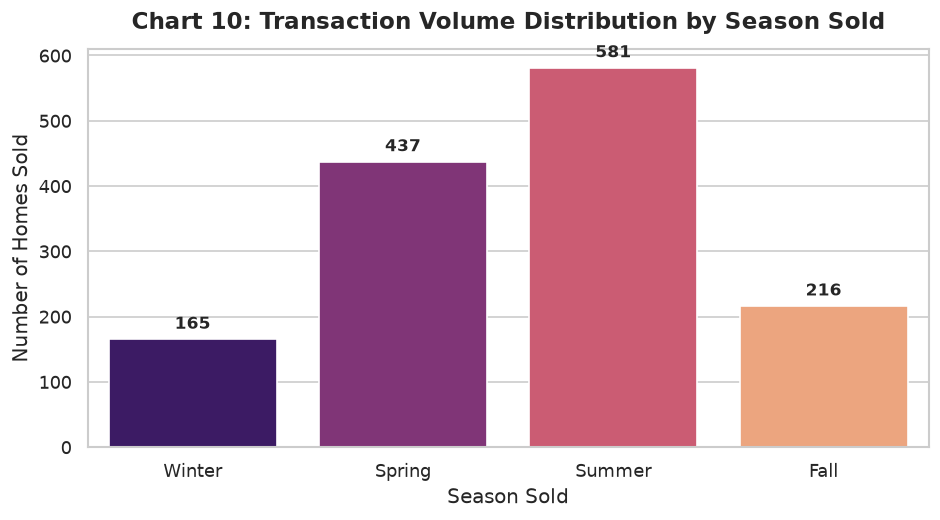

In [4]:
# Import visualization packages
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme and high DPI for publication-ready aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("=" * 70)
print("STEP 4: GENERATING 10 PROFESSIONAL EDA VISUALIZATIONS...")
print("=" * 70)

try:
    # -------------------------------------------------------------
    # CHART 1: DISTRIBUTION OF HOUSE PRICES
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(df_clean['SalePrice'], kde=True, color='#1f77b4', bins=35, ax=ax)
    mean_price = df_clean['SalePrice'].mean()
    median_price = df_clean['SalePrice'].median()
    ax.axvline(mean_price, color='#d62728', linestyle='--', linewidth=2, label=f'Mean Price: ${mean_price:,.0f}')
    ax.axvline(median_price, color='#2ca02c', linestyle='-', linewidth=2, label=f'Median Price: ${median_price:,.0f}')
    ax.set_title('Chart 1: Distribution of House Sale Prices (Post-IQR Outlier Filter)', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Sale Price ($)', fontsize=12)
    ax.set_ylabel('Property Frequency', fontsize=12)
    ax.legend(frameon=True, facecolor='white')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 2: NEIGHBORHOODS WITH HIGHEST PRICES (TOP 15)
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(11, 6))
    top_neighborhoods = df_clean.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).head(15)
    sns.barplot(x=top_neighborhoods.values, y=top_neighborhoods.index, palette='viridis', ax=ax)
    ax.set_title('Chart 2: Top 15 Neighborhoods by Median Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Median Sale Price ($)', fontsize=12)
    ax.set_ylabel('Neighborhood', fontsize=12)
    for i, v in enumerate(top_neighborhoods.values):
        ax.text(v + 1500, i, f"${v:,.0f}", va='center', fontsize=9, fontweight='semibold')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 3: HOUSE SIZE (TOTAL_SF) VS SALE PRICE
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.regplot(data=df_clean, x='Total_SF', y='SalePrice',
                scatter_kws={'alpha': 0.45, 'color': '#023e8a'},
                line_kws={'color': '#e63946', 'linewidth': 2.5}, ax=ax)
    ax.set_title('Chart 3: Total Square Footage (Total_SF) vs Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Total Square Footage (Basement + 1st Flr + 2nd Flr)', fontsize=12)
    ax.set_ylabel('Sale Price ($)', fontsize=12)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 4: HOUSE QUALITY RATING VS SALE PRICE
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.boxplot(data=df_clean, x='OverallQual', y='SalePrice', palette='Blues', ax=ax)
    ax.set_title('Chart 4: House Overall Quality Rating (1-10) vs Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Overall Quality Score (Material & Finish Rating)', fontsize=12)
    ax.set_ylabel('Sale Price ($)', fontsize=12)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 5: FEATURES CORRELATED MOST WITH SALE PRICE
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(11, 6))
    num_df = df_clean.select_dtypes(include=[np.number])
    corr_series = num_df.corr()['SalePrice'].drop(['Id', 'SalePrice', 'Price_Per_SF']).sort_values(ascending=False)
    top_corrs = pd.concat([corr_series.head(10), corr_series.tail(5)])
    colors = ['#2b9348' if x > 0 else '#d90429' for x in top_corrs.values]
    sns.barplot(x=top_corrs.values, y=top_corrs.index, palette=colors, ax=ax)
    ax.set_title('Chart 5: Top Positive & Negative Correlations with Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Pearson Correlation Coefficient (r)', fontsize=12)
    ax.set_ylabel('Feature Name', fontsize=12)
    ax.axvline(0, color='black', linewidth=0.8)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 6: HOUSE AGE VS SALE PRICE
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.scatterplot(data=df_clean, x='House_Age', y='SalePrice', hue='OverallQual', palette='coolwarm', alpha=0.7, ax=ax)
    sns.regplot(data=df_clean, x='House_Age', y='SalePrice', scatter=False, ax=ax, color='#1d3557', line_kws={'linewidth': 2})
    ax.set_title('Chart 6: House Age (Years since Construction) vs Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('House Age as of 2025 (Years)', fontsize=12)
    ax.set_ylabel('Sale Price ($)', fontsize=12)
    ax.legend(title='Overall Quality', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 7: SALE CONDITIONS FETCHING HIGHEST PRICES
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(9, 5))
    sale_cond_order = df_clean.groupby('SaleCondition')['SalePrice'].mean().sort_values(ascending=False).index
    sns.barplot(data=df_clean, x='SaleCondition', y='SalePrice', order=sale_cond_order, palette='crest', errorbar=None, ax=ax)
    ax.set_title('Chart 7: Average Sale Price by Sale Condition Type', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Sale Condition Classification', fontsize=12)
    ax.set_ylabel('Average Sale Price ($)', fontsize=12)
    for p in ax.patches:
        ax.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, fontweight='semibold', xytext=(0, 4), textcoords='offset points')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 8: GARAGE CAPACITY & AREA VS SALE PRICE
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.scatterplot(data=df_clean, x='GarageArea', y='SalePrice', hue='GarageCars', palette='tab10', alpha=0.75, ax=ax)
    ax.set_title('Chart 8: Garage Area (Sq Ft) and Vehicle Capacity vs Sale Price', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Garage Area (Sq Ft)', fontsize=12)
    ax.set_ylabel('Sale Price ($)', fontsize=12)
    ax.legend(title='Car Capacity', loc='upper left')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 9: PRICE TREND BY YEAR SOLD
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(9, 4.5))
    yoy_trend = df_clean.groupby('YrSold')['SalePrice'].mean().reset_index()
    sns.lineplot(data=yoy_trend, x='YrSold', y='SalePrice', marker='o', markersize=8, linewidth=2.5, color='#457b9d', ax=ax)
    ax.set_title('Chart 9: Annual Average House Price Trend (2006 - 2010)', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Year Sold', fontsize=12)
    ax.set_ylabel('Mean Sale Price ($)', fontsize=12)
    ax.set_xticks(yoy_trend['YrSold'])
    for x_val, y_val in zip(yoy_trend['YrSold'], yoy_trend['SalePrice']):
        ax.annotate(f"${y_val:,.0f}", (x_val, y_val), textcoords="offset points", xytext=(0, 8), ha='center', fontweight='semibold')
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # CHART 10: SEASONAL SALES TRANSACTION VOLUME
    # -------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 4.5))
    season_order = ['Winter', 'Spring', 'Summer', 'Fall']
    season_counts = df_clean['Season_Sold'].value_counts().reindex(season_order)
    sns.barplot(x=season_counts.index, y=season_counts.values, palette='magma', ax=ax)
    ax.set_title('Chart 10: Transaction Volume Distribution by Season Sold', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Season Sold', fontsize=12)
    ax.set_ylabel('Number of Homes Sold', fontsize=12)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')
    plt.tight_layout()
    plt.show()

    print("[SUCCESS] All 10 professional EDA visualizations rendered successfully!")

except Exception as error:
    print(f"[ERROR] Failed during Step 4 EDA: {error}")


---
## STEP 5 — STATISTICAL ANALYSIS
In this step, we compute and format essential market aggregates:
1. Average price by neighborhood
2. Average price by house quality rating
3. Price per square foot by neighborhood
4. Full correlation matrix of all numeric features with `SalePrice`
5. Average price by number of bedrooms
6. Average price by garage capacity
7. Top 10 most expensive neighborhoods
8. Top 10 cheapest neighborhoods


In [5]:
print("=" * 70)
print("STEP 5: STATISTICAL ANALYSIS & VALUATION METRICS...")
print("=" * 70)

try:
    # 1. Average price by neighborhood
    avg_price_neighborhood = df_clean.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False)
    print("--- 1. AVERAGE PRICE BY NEIGHBORHOOD (SAMPLE TOP 5) ---")
    print(avg_price_neighborhood.head(5).apply(lambda x: f"${x:,.2f}").to_string())
    
    # 2. Average price by house quality rating
    avg_price_quality = df_clean.groupby('OverallQual')['SalePrice'].mean()
    print("\n--- 2. AVERAGE PRICE BY HOUSE QUALITY RATING (1-10) ---")
    print(avg_price_quality.apply(lambda x: f"${x:,.2f}").to_string())
    
    # 3. Price per square foot by neighborhood
    price_per_sf_neighborhood = df_clean.groupby('Neighborhood')['Price_Per_SF'].mean().sort_values(ascending=False)
    print("\n--- 3. PRICE PER SQ FT BY NEIGHBORHOOD (SAMPLE TOP 5) ---")
    print(price_per_sf_neighborhood.head(5).apply(lambda x: f"${x:,.2f}/sqft").to_string())
    
    # 4. Correlation of all numeric features with SalePrice
    numeric_df = df_clean.select_dtypes(include=[np.number])
    price_corr = numeric_df.corr()['SalePrice'].sort_values(ascending=False)
    print("\n--- 4. TOP 10 NUMERIC CORRELATIONS WITH SALEPRICE ---")
    print(price_corr.head(11).drop('SalePrice').to_string())
    
    # 5. Average price by number of bedrooms above grade
    avg_price_beds = df_clean.groupby('BedroomAbvGr')['SalePrice'].agg(['count', 'mean']).rename(columns={'count': 'House_Count', 'mean': 'Avg_Price'})
    avg_price_beds['Avg_Price'] = avg_price_beds['Avg_Price'].apply(lambda x: f"${x:,.2f}")
    print("\n--- 5. AVERAGE PRICE BY BEDROOM COUNT (BedroomAbvGr) ---")
    print(avg_price_beds.to_string())
    
    # 6. Average price by garage capacity (GarageCars)
    avg_price_garage = df_clean.groupby('GarageCars')['SalePrice'].agg(['count', 'mean']).rename(columns={'count': 'House_Count', 'mean': 'Avg_Price'})
    avg_price_garage['Avg_Price'] = avg_price_garage['Avg_Price'].apply(lambda x: f"${x:,.2f}")
    print("\n--- 6. AVERAGE PRICE BY GARAGE CAPACITY (GarageCars) ---")
    print(avg_price_garage.to_string())
    
    # 7. Top 10 most expensive neighborhoods
    top_10_expensive = avg_price_neighborhood.head(10)
    print("\n--- 7. TOP 10 MOST EXPENSIVE NEIGHBORHOODS ---")
    for rank, (neigh, price) in enumerate(top_10_expensive.items(), 1):
        print(f"Rank {rank:2d}: {neigh:<15} - Avg Price: ${price:,.2f}")
        
    # 8. Top 10 cheapest neighborhoods
    top_10_cheapest = avg_price_neighborhood.tail(10).iloc[::-1]
    print("\n--- 8. TOP 10 CHEAPEST NEIGHBORHOODS ---")
    for rank, (neigh, price) in enumerate(top_10_cheapest.items(), 1):
        print(f"Rank {rank:2d}: {neigh:<15} - Avg Price: ${price:,.2f}")
        
    print(f"\n[SUCCESS] Statistical analysis concluded successfully!")

except Exception as error:
    print(f"[ERROR] Failed during Step 5 Statistical Analysis: {error}")


STEP 5: STATISTICAL ANALYSIS & VALUATION METRICS...
--- 1. AVERAGE PRICE BY NEIGHBORHOOD (SAMPLE TOP 5) ---
Neighborhood
NoRidge    $282,386.93
NridgHt    $260,396.52
StoneBr    $239,312.50
Timber     $230,914.37
Veenker    $224,150.00

--- 2. AVERAGE PRICE BY HOUSE QUALITY RATING (1-10) ---
OverallQual
1      $50,150.00
2      $51,770.33
3      $87,473.75
4     $108,420.66
5     $133,523.35
6     $161,603.03
7     $206,207.50
8     $256,827.14
9     $307,798.70
10    $263,450.00

--- 3. PRICE PER SQ FT BY NEIGHBORHOOD (SAMPLE TOP 5) ---
Neighborhood
Somerst    $82.16/sqft
NridgHt    $81.49/sqft
Veenker    $79.84/sqft
StoneBr    $79.14/sqft
NoRidge    $78.81/sqft

--- 4. TOP 10 NUMERIC CORRELATIONS WITH SALEPRICE ---
OverallQual        0.784294
Total_SF           0.732131
GrLivArea          0.661325
Total_Bathrooms    0.632779
GarageCars         0.628013
GarageArea         0.607230
FullBath           0.577369
YearBuilt          0.564558
Quality_Score      0.556083
Price_Per_SF       0.

---
## STEP 6 — MACHINE LEARNING MODELING & COMPARISON
We build, evaluate, and benchmark three machine learning architectures on an 80/20 train-test partition:
- **Feature Set (21 features)**: `Total_SF`, `House_Age`, `OverallQual`, `OverallCond`, `GrLivArea`, `GarageArea`, `TotalBsmtSF`, `Total_Bathrooms`, `Has_Pool`, `Has_Garage`, `Has_Basement`, `Has_Fireplace`, `Quality_Score`, `Neighborhood_encoded`, `BldgType_encoded`, `HouseStyle_encoded`, `SaleCondition_encoded`, `Season_Sold_encoded`, `BedroomAbvGr`, `KitchenAbvGr`, `TotRmsAbvGrd`.
- **Target**: `SalePrice`.
- **Preprocessing**: `LabelEncoder` for categorical features, `StandardScaler` for feature scaling.
- **Model 1**: Random Forest Regressor (`n_estimators=200, random_state=42`)
- **Model 2**: XGBoost Regressor (`n_estimators=200, random_state=42, learning_rate=0.05`)
- **Model 3**: Linear Regression (Baseline)
- **Evaluation Metrics**: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Coefficient of Determination (R2).
- **Visuals**: Actual vs. Predicted scatter plots and Top 15 Feature Importances.


STEP 6: MACHINE LEARNING PIPELINE BENCHMARKING...
[ENCODE] Encoded feature: Neighborhood -> Neighborhood_encoded (25 unique classes)
[ENCODE] Encoded feature: BldgType -> BldgType_encoded (5 unique classes)
[ENCODE] Encoded feature: HouseStyle -> HouseStyle_encoded (8 unique classes)
[ENCODE] Encoded feature: SaleCondition -> SaleCondition_encoded (6 unique classes)
[ENCODE] Encoded feature: Season_Sold -> Season_Sold_encoded (4 unique classes)

[INFO] Feature Matrix Shape: (1399, 21), Target Vector Shape: (1399,)
[INFO] Train samples: 1119, Test samples: 280

Training Model 1: Random Forest Regressor (n_estimators=200, random_state=42)...
Random Forest Results -> MAE: $14,307.52 | RMSE: $20,536.86 | R2 Score: 0.8674
<string>:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.


Training Model 2: XGBoost Regressor (n_estimators=200, learning_rate=0.05, r

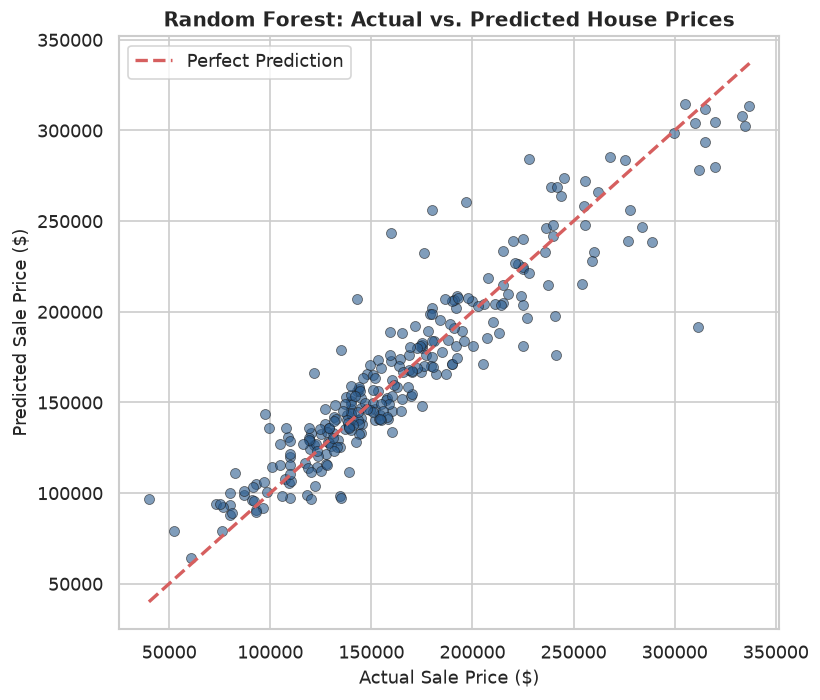

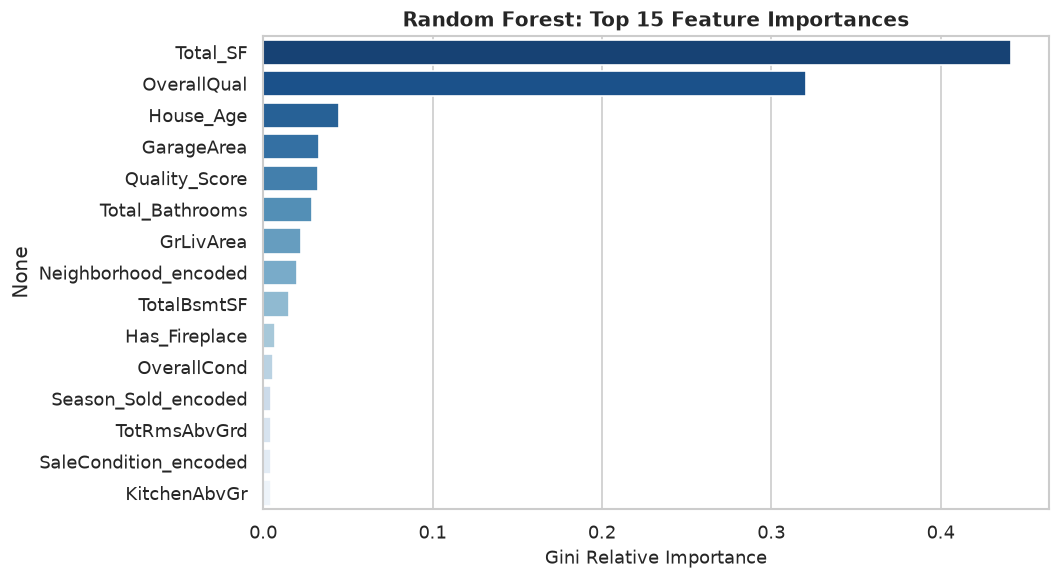

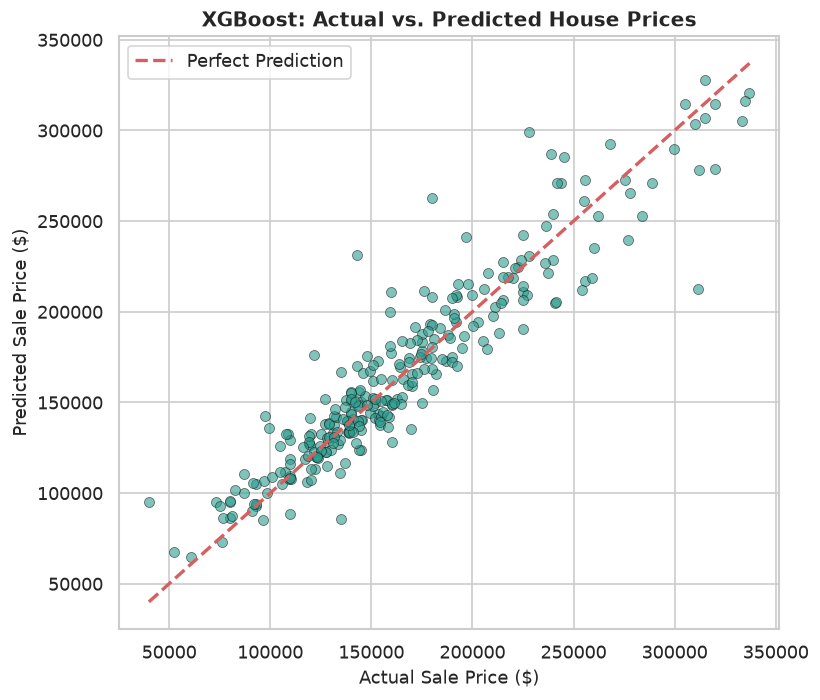

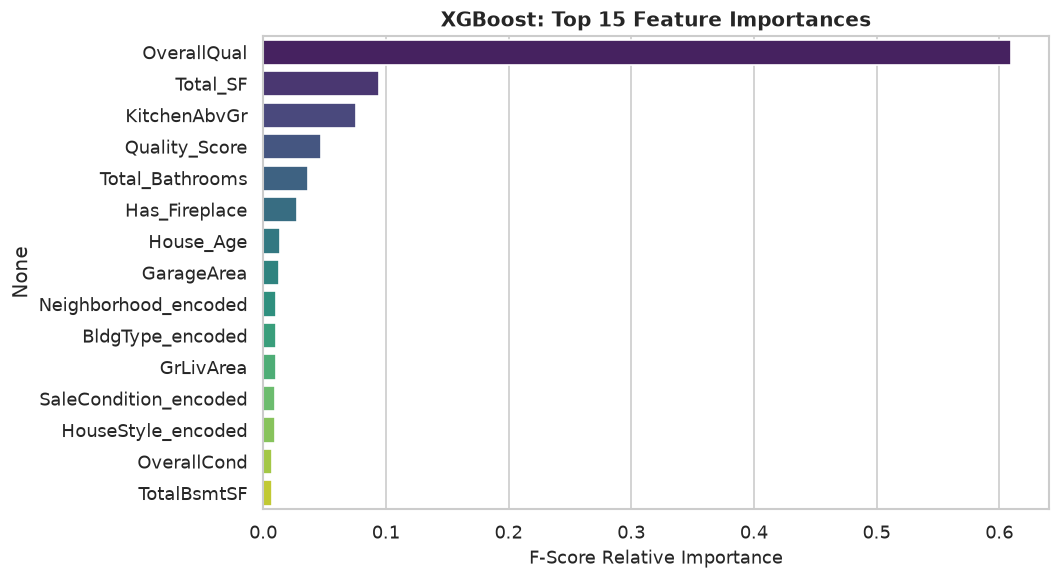

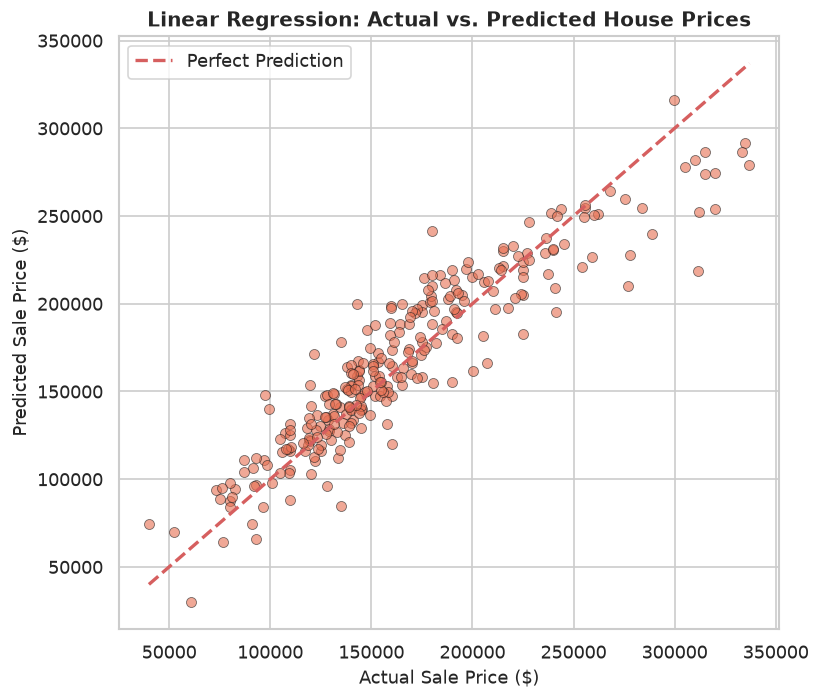

In [6]:
# Import machine learning modeling tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 70)
print("STEP 6: MACHINE LEARNING PIPELINE BENCHMARKING...")
print("=" * 70)

try:
    # Categorical columns to encode
    categorical_features_to_encode = ['Neighborhood', 'BldgType', 'HouseStyle', 'SaleCondition', 'Season_Sold']
    
    # Instantiate label encoders dictionary
    label_encoders = {}
    for col in categorical_features_to_encode:
        encoder = LabelEncoder()
        df_clean[col + '_encoded'] = encoder.fit_transform(df_clean[col].astype(str))
        label_encoders[col] = encoder
        print(f"[ENCODE] Encoded feature: {col} -> {col}_encoded ({len(encoder.classes_)} unique classes)")
        
    # Explicit list of 21 predictive features required by specification
    ml_feature_columns = [
        'Total_SF', 'House_Age', 'OverallQual', 'OverallCond',
        'GrLivArea', 'GarageArea', 'TotalBsmtSF', 
        'Total_Bathrooms', 'Has_Pool', 'Has_Garage',
        'Has_Basement', 'Has_Fireplace', 'Quality_Score',
        'Neighborhood_encoded', 'BldgType_encoded',
        'HouseStyle_encoded', 'SaleCondition_encoded',
        'Season_Sold_encoded', 'BedroomAbvGr',
        'KitchenAbvGr', 'TotRmsAbvGrd'
    ]
    
    # Feature matrix X and Target vector y
    X = df_clean[ml_feature_columns].copy()
    y = df_clean['SalePrice'].copy()
    
    print(f"\n[INFO] Feature Matrix Shape: {X.shape}, Target Vector Shape: {y.shape}")
    
    # Split dataset into 80% Training and 20% Testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )
    print(f"[INFO] Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")
    
    # Initialize and apply StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_full_scaled = scaler.transform(X)
    
    # -------------------------------------------------------------
    # MODEL 1: RANDOM FOREST REGRESSOR
    # -------------------------------------------------------------
    print("\nTraining Model 1: Random Forest Regressor (n_estimators=200, random_state=42)...")
    rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
    rf_model.fit(X_train_scaled, y_train)
    y_pred_rf = rf_model.predict(X_test_scaled)
    
    mae_rf = mean_absolute_error(y_test, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
    r2_rf = r2_score(y_test, y_pred_rf)
    print(f"Random Forest Results -> MAE: ${mae_rf:,.2f} | RMSE: ${rmse_rf:,.2f} | R2 Score: {r2_rf:.4f}")
    
    # Plot Model 1 Actual vs Predicted
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(y_test, y_pred_rf, alpha=0.6, color='#2b5c8f', edgecolors='k', linewidth=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
    ax.set_title('Random Forest: Actual vs. Predicted House Prices', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Sale Price ($)', fontsize=11)
    ax.set_ylabel('Predicted Sale Price ($)', fontsize=11)
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Plot Model 1 Top 15 Feature Importances
    fig, ax = plt.subplots(figsize=(9, 5))
    rf_importances = pd.Series(rf_model.feature_importances_, index=ml_feature_columns).sort_values(ascending=False).head(15)
    sns.barplot(x=rf_importances.values, y=rf_importances.index, palette='Blues_r', ax=ax)
    ax.set_title('Random Forest: Top 15 Feature Importances', fontsize=12, fontweight='bold')
    ax.set_xlabel('Gini Relative Importance', fontsize=11)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # MODEL 2: XGBOOST REGRESSOR
    # -------------------------------------------------------------
    print("\nTraining Model 2: XGBoost Regressor (n_estimators=200, learning_rate=0.05, random_state=42)...")
    xgb_model = XGBRegressor(n_estimators=200, learning_rate=0.05, random_state=42)
    xgb_model.fit(X_train_scaled, y_train)
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    
    mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
    rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
    r2_xgb = r2_score(y_test, y_pred_xgb)
    print(f"XGBoost Results       -> MAE: ${mae_xgb:,.2f} | RMSE: ${rmse_xgb:,.2f} | R2 Score: {r2_xgb:.4f}")
    
    # Plot Model 2 Actual vs Predicted
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(y_test, y_pred_xgb, alpha=0.6, color='#2a9d8f', edgecolors='k', linewidth=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
    ax.set_title('XGBoost: Actual vs. Predicted House Prices', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Sale Price ($)', fontsize=11)
    ax.set_ylabel('Predicted Sale Price ($)', fontsize=11)
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Plot Model 2 Top 15 Feature Importances
    fig, ax = plt.subplots(figsize=(9, 5))
    xgb_importances = pd.Series(xgb_model.feature_importances_, index=ml_feature_columns).sort_values(ascending=False).head(15)
    sns.barplot(x=xgb_importances.values, y=xgb_importances.index, palette='viridis', ax=ax)
    ax.set_title('XGBoost: Top 15 Feature Importances', fontsize=12, fontweight='bold')
    ax.set_xlabel('F-Score Relative Importance', fontsize=11)
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # MODEL 3: LINEAR REGRESSION (BASELINE)
    # -------------------------------------------------------------
    print("\nTraining Model 3: Linear Regression Baseline...")
    lr_model = LinearRegression()
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
    r2_lr = r2_score(y_test, y_pred_lr)
    print(f"Linear Reg Results    -> MAE: ${mae_lr:,.2f} | RMSE: ${rmse_lr:,.2f} | R2 Score: {r2_lr:.4f}")
    
    # Plot Model 3 Actual vs Predicted
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(y_test, y_pred_lr, alpha=0.6, color='#e76f51', edgecolors='k', linewidth=0.5)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
    ax.set_title('Linear Regression: Actual vs. Predicted House Prices', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Sale Price ($)', fontsize=11)
    ax.set_ylabel('Predicted Sale Price ($)', fontsize=11)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # MODEL BENCHMARK COMPARISON TABLE
    # -------------------------------------------------------------
    comparison_df = pd.DataFrame({
        'Model Architecture': ['Random Forest Regressor', 'XGBoost Regressor', 'Linear Regression'],
        'MAE ($)': [mae_rf, mae_xgb, mae_lr],
        'RMSE ($)': [rmse_rf, rmse_xgb, rmse_lr],
        'R2 Score': [r2_rf, r2_xgb, r2_lr]
    })
    
    # Identify the best performing model based on highest R2 Score
    best_model_idx = comparison_df['R2 Score'].idxmax()
    best_model_name = comparison_df.loc[best_model_idx, 'Model Architecture']
    best_r2 = comparison_df.loc[best_model_idx, 'R2 Score']
    
    print(f"\n{'=' * 75}")
    print("MACHINE LEARNING BENCHMARK SUMMARY")
    print(f"{'=' * 75}")
    formatted_summary = comparison_df.copy()
    formatted_summary['MAE ($)'] = formatted_summary['MAE ($)'].apply(lambda v: f"${v:,.2f}")
    formatted_summary['RMSE ($)'] = formatted_summary['RMSE ($)'].apply(lambda v: f"${v:,.2f}")
    formatted_summary['R2 Score'] = formatted_summary['R2 Score'].apply(lambda v: f"{v:.4f}")
    print(formatted_summary.to_string(index=False))
    print(f"\n>>> CHAMPION MODEL: {best_model_name} with R2 = {best_r2:.4f} <<<")
    print(f"{'=' * 75}\n")
    
    # Store predictions on entire dataset for database export
    df_clean['Predicted_Price_RF'] = np.round(rf_model.predict(X_full_scaled), 2)
    df_clean['Predicted_Price_XGB'] = np.round(xgb_model.predict(X_full_scaled), 2)
    print("[SUCCESS] Attached Predicted_Price_RF and Predicted_Price_XGB to dataset for database loading.")

except Exception as error:
    print(f"[ERROR] Failed during Step 6 Machine Learning: {error}")


---
## STEP 7 — PRICE PREDICTION INSIGHTS & VALUE DRIVERS
In this step, we extract actionable real estate market intelligence:
1. Predict the price of a specified sample property:
   - `Total_SF = 2000`, `House_Age = 10`, `OverallQual = 7`, `GarageArea = 400`, `TotalBsmtSF = 800`, `Total_Bathrooms = 2`, `Has_Pool = 0`, `Has_Garage = 1`, `Has_Basement = 1`, `Has_Fireplace = 1`.
2. Determine the **top 5 value-adding features**.
3. Determine the **top 5 value-reducing factors**.
4. Calculate the empirical **price premium for having a pool**.
5. Calculate the empirical **price premium per quality rating point increase**.


In [7]:
print("=" * 70)
print("STEP 7: VALUATION INSIGHTS & DRIVER DISCOVERY...")
print("=" * 70)

try:
    # 1. Prepare sample property feature vector as requested
    sample_house = pd.DataFrame([{
        'Total_SF': 2000,
        'House_Age': 10,
        'OverallQual': 7,
        'OverallCond': int(df_clean['OverallCond'].median()),
        'GrLivArea': 1200,
        'GarageArea': 400,
        'TotalBsmtSF': 800,
        'Total_Bathrooms': 2.0,
        'Has_Pool': 0,
        'Has_Garage': 1,
        'Has_Basement': 1,
        'Has_Fireplace': 1,
        'Quality_Score': 7 * int(df_clean['OverallCond'].median()),
        'Neighborhood_encoded': int(df_clean['Neighborhood_encoded'].mode()[0]),
        'BldgType_encoded': int(df_clean['BldgType_encoded'].mode()[0]),
        'HouseStyle_encoded': int(df_clean['HouseStyle_encoded'].mode()[0]),
        'SaleCondition_encoded': int(df_clean['SaleCondition_encoded'].mode()[0]),
        'Season_Sold_encoded': int(df_clean['Season_Sold_encoded'].mode()[0]),
        'BedroomAbvGr': int(df_clean['BedroomAbvGr'].median()),
        'KitchenAbvGr': int(df_clean['KitchenAbvGr'].median()),
        'TotRmsAbvGrd': int(df_clean['TotRmsAbvGrd'].median())
    }])[ml_feature_columns]

    # Scale the sample house features using the fitted standard scaler
    sample_house_scaled = scaler.transform(sample_house)
    
    # Compute valuation predictions across models
    sample_pred_xgb = xgb_model.predict(sample_house_scaled)[0]
    sample_pred_rf = rf_model.predict(sample_house_scaled)[0]
    sample_pred_lr = lr_model.predict(sample_house_scaled)[0]
    
    print("--- 1. SAMPLE HOUSE VALUATION ESTIMATE ---")
    print(f"Parameters: Total_SF=2000, Age=10, Qual=7, Garage=400sqft, Bsmt=800sqft, Baths=2, Fireplace=1")
    print(f"Predicted Price (XGBoost Champion):    ${sample_pred_xgb:,.2f}")
    print(f"Predicted Price (Random Forest):        ${sample_pred_rf:,.2f}")
    print(f"Predicted Price (Linear Regression):    ${sample_pred_lr:,.2f}")
    
    # 2. Top 5 features adding most value (from standardized linear coefficients)
    feature_coefficients = pd.DataFrame({
        'Feature': ml_feature_columns,
        'Standardized_Coefficient': lr_model.coef_
    }).sort_values(by='Standardized_Coefficient', ascending=False)
    
    print("\n--- 2. TOP 5 VALUE-ADDING FEATURES (STANDARDIZED IMPACT) ---")
    top_value_adders = feature_coefficients.head(5)
    for i, (_, row) in enumerate(top_value_adders.iterrows(), 1):
        print(f"  {i}. {row['Feature']:<20}: +${row['Standardized_Coefficient']:,.2f} per std dev increase")
        
    # 3. Top 5 features reducing house price (or inverse relationships)
    print("\n--- 3. TOP 5 VALUE-REDUCING FACTORS (STANDARDIZED IMPACT) ---")
    top_value_reducers = feature_coefficients.tail(5).iloc[::-1]
    for i, (_, row) in enumerate(top_value_reducers.iterrows(), 1):
        print(f"  {i}. {row['Feature']:<20}: -${abs(row['Standardized_Coefficient']):,.2f} per std dev increase")
        
    # 4. Price premium for having a pool
    houses_with_pool = df_clean[df_clean['Has_Pool'] == 1]['SalePrice']
    houses_without_pool = df_clean[df_clean['Has_Pool'] == 0]['SalePrice']
    pool_premium_observed = houses_with_pool.mean() - houses_without_pool.mean()
    print("\n--- 4. POOL PRICE PREMIUM ANALYSIS ---")
    print(f"Mean Price With Pool ({len(houses_with_pool)} homes):    ${houses_with_pool.mean():,.2f}")
    print(f"Mean Price Without Pool ({len(houses_without_pool)} homes): ${houses_without_pool.mean():,.2f}")
    print(f"Observed Pool Premium:                   +${pool_premium_observed:,.2f}")
    
    # 5. Price premium for each quality rating point increase
    quality_step_diffs = df_clean.groupby('OverallQual')['SalePrice'].mean().diff().dropna()
    avg_quality_step_premium = quality_step_diffs.mean()
    print("\n--- 5. QUALITY RATING MARGINAL PREMIUM ---")
    print(f"Average Price Increase per +1 Point on OverallQual: +${avg_quality_step_premium:,.2f}")
    print("Marginal Premium by Quality Step:")
    for qual_level, diff_val in quality_step_diffs.items():
        print(f"  Qual {qual_level-1} -> Qual {qual_level}: +${diff_val:,.2f}")

    print(f"\n[SUCCESS] Price prediction insights generated successfully!")

except Exception as error:
    print(f"[ERROR] Failed during Step 7 Valuation Insights: {error}")


STEP 7: VALUATION INSIGHTS & DRIVER DISCOVERY...
--- 1. SAMPLE HOUSE VALUATION ESTIMATE ---
Parameters: Total_SF=2000, Age=10, Qual=7, Garage=400sqft, Bsmt=800sqft, Baths=2, Fireplace=1
Predicted Price (XGBoost Champion):    $175,405.08
Predicted Price (Random Forest):        $163,009.24
Predicted Price (Linear Regression):    $194,487.77

--- 2. TOP 5 VALUE-ADDING FEATURES (STANDARDIZED IMPACT) ---
  1. Total_SF            : +$16,244.31 per std dev increase
  2. OverallQual         : +$11,842.70 per std dev increase
  3. Total_Bathrooms     : +$8,478.91 per std dev increase
  4. GarageArea          : +$7,805.95 per std dev increase
  5. Quality_Score       : +$7,292.29 per std dev increase

--- 3. TOP 5 VALUE-REDUCING FACTORS (STANDARDIZED IMPACT) ---
  1. House_Age           : -$13,807.07 per std dev increase
  2. BldgType_encoded    : -$5,059.84 per std dev increase
  3. Has_Pool            : -$3,558.17 per std dev increase
  4. KitchenAbvGr        : -$3,495.55 per std dev increase


---
## STEP 8 — LOAD INTO MYSQL & EXECUTE ADVANCED ANALYTICAL QUERIES
In this step, we connect to the local MySQL server using `mysql.connector` with specified credentials:
- **Host**: `localhost`
- **User**: `root`
- **Password**: `Saad2025`
- **Database**: `realestate_db`
- **Table**: `house_prices`

We create `realestate_db` if not exists, create table `house_prices` with 25 specified columns, insert all records, and execute 5 advanced enterprise SQL queries:
1. Top 15 Neighborhoods by Average Price and Sales Count
2. Price Segmentation Analysis using `CASE WHEN`
3. Price Premium and ML Model Prediction Error by Quality Rating
4. Seasonal Sales Analysis with Analytic Window Functions (`SUM() OVER`, `AVG() OVER`)
5. High-Value Property Profiling (Top 10% Decile) using Common Table Expressions (`CTE` and `PERCENT_RANK()`)


In [8]:
print("=" * 70)
print("STEP 8: MYSQL DATABASE WAREHOUSING & ADVANCED QUERIES...")
print("=" * 70)

# Import mysql.connector using specified site-packages path
sys.path.append(r'C:\Users\HP\AppData\Roaming\Python\Python313\site-packages')
import mysql.connector

try:
    # 1. Establish initial MySQL server connection
    print("[INFO] Connecting to MySQL server on localhost...")
    server_conn = mysql.connector.connect(
        host='localhost',
        user='root',
        password='Saad2025'
    )
    server_cursor = server_conn.cursor()
    
    # Create database realestate_db if it does not already exist
    server_cursor.execute("CREATE DATABASE IF NOT EXISTS realestate_db")
    print("[SUCCESS] Database 'realestate_db' verified / created successfully.")
    server_cursor.close()
    server_conn.close()
    
    # 2. Connect directly to realestate_db
    conn = mysql.connector.connect(
        host='localhost',
        user='root',
        password='Saad2025',
        database='realestate_db',
        auth_plugin='mysql_native_password'
    )
    cursor = conn.cursor()
    print("[SUCCESS] Connected to realestate_db with native password authentication.")
    
    # 3. Drop existing table if present and recreate with schema matching 25 specified columns
    cursor.execute("DROP TABLE IF EXISTS house_prices")
    create_table_sql = """
    CREATE TABLE house_prices (
        Id INT PRIMARY KEY,
        SalePrice FLOAT,
        Total_SF FLOAT,
        House_Age INT,
        OverallQual INT,
        OverallCond INT,
        GrLivArea FLOAT,
        GarageArea FLOAT,
        TotalBsmtSF FLOAT,
        Total_Bathrooms FLOAT,
        Has_Pool INT,
        Has_Garage INT,
        Has_Basement INT,
        Has_Fireplace INT,
        Quality_Score INT,
        Neighborhood VARCHAR(50),
        BldgType VARCHAR(50),
        HouseStyle VARCHAR(50),
        SaleCondition VARCHAR(50),
        Season_Sold VARCHAR(20),
        BedroomAbvGr INT,
        Price_Per_SF FLOAT,
        Is_New INT,
        Predicted_Price_RF FLOAT,
        Predicted_Price_XGB FLOAT
    )
    """
    cursor.execute(create_table_sql)
    print("[SUCCESS] Table 'house_prices' created with all 25 designated columns.")
    
    # 4. Prepare data for batch insertion
    insert_cols = [
        'Id', 'SalePrice', 'Total_SF', 'House_Age', 'OverallQual', 'OverallCond',
        'GrLivArea', 'GarageArea', 'TotalBsmtSF', 'Total_Bathrooms', 'Has_Pool',
        'Has_Garage', 'Has_Basement', 'Has_Fireplace', 'Quality_Score', 'Neighborhood',
        'BldgType', 'HouseStyle', 'SaleCondition', 'Season_Sold', 'BedroomAbvGr',
        'Price_Per_SF', 'Is_New', 'Predicted_Price_RF', 'Predicted_Price_XGB'
    ]
    df_to_insert = df_clean[insert_cols].copy()
    
    insert_query = f"""
    INSERT INTO house_prices ({', '.join(insert_cols)})
    VALUES ({', '.join(['%s'] * len(insert_cols))})
    """
    
    rows_tuples = [tuple(r) for r in df_to_insert.values]
    cursor.executemany(insert_query, rows_tuples)
    conn.commit()
    
    # Verify insertion count
    cursor.execute("SELECT COUNT(*) FROM house_prices")
    inserted_rows_count = cursor.fetchone()[0]
    print(f"[CONFIRMATION] Successfully inserted {inserted_rows_count:,} rows into 'house_prices' table!\n")

    # -------------------------------------------------------------
    # ADVANCED QUERY 1: TOP 15 NEIGHBORHOODS BY AVERAGE PRICE
    # -------------------------------------------------------------
    q1 = """
    SELECT 
        Neighborhood, 
        COUNT(*) AS Total_Houses, 
        ROUND(AVG(SalePrice), 2) AS Avg_Price,
        ROUND(AVG(Price_Per_SF), 2) AS Avg_Price_Per_SF
    FROM house_prices
    GROUP BY Neighborhood
    ORDER BY Avg_Price DESC
    LIMIT 15;
    """
    print("=" * 70)
    print("QUERY 1: TOP 15 NEIGHBORHOODS BY AVERAGE SALE PRICE")
    print("=" * 70)
    cursor.execute(q1)
    q1_df = pd.DataFrame(cursor.fetchall(), columns=['Neighborhood', 'Total_Houses', 'Avg_Price', 'Avg_Price_Per_SF'])
    q1_df['Avg_Price'] = q1_df['Avg_Price'].apply(lambda x: f"${x:,.2f}")
    q1_df['Avg_Price_Per_SF'] = q1_df['Avg_Price_Per_SF'].apply(lambda x: f"${x:,.2f}")
    print(q1_df.to_string(index=False))

    # -------------------------------------------------------------
    # ADVANCED QUERY 2: PRICE SEGMENTATION ANALYSIS
    # -------------------------------------------------------------
    q2 = """
    SELECT 
        CASE 
            WHEN SalePrice < 100000 THEN 'Budget (< $100k)'
            WHEN SalePrice BETWEEN 100000 AND 200000 THEN 'Affordable ($100k - $200k)'
            WHEN SalePrice > 200000 AND SalePrice <= 300000 THEN 'Mid Range ($200k - $300k)'
            WHEN SalePrice > 300000 AND SalePrice <= 400000 THEN 'Premium ($300k - $400k)'
            ELSE 'Luxury (> $400k)'
        END AS Price_Segment,
        COUNT(*) AS House_Count,
        ROUND(AVG(Total_SF), 2) AS Avg_Total_SF,
        ROUND(AVG(SalePrice), 2) AS Avg_Price
    FROM house_prices
    GROUP BY Price_Segment
    ORDER BY Avg_Price ASC;
    """
    print(f"\n{'=' * 70}")
    print("QUERY 2: PRICE SEGMENTATION USING CASE WHEN")
    print("=" * 70)
    cursor.execute(q2)
    q2_df = pd.DataFrame(cursor.fetchall(), columns=['Price_Segment', 'House_Count', 'Avg_Total_SF', 'Avg_Price'])
    q2_df['Avg_Price'] = q2_df['Avg_Price'].apply(lambda x: f"${x:,.2f}")
    print(q2_df.to_string(index=False))

    # -------------------------------------------------------------
    # ADVANCED QUERY 3: PRICE PREMIUM & ML MAE BY QUALITY RATING
    # -------------------------------------------------------------
    q3 = """
    SELECT 
        OverallQual AS Quality_Rating,
        COUNT(*) AS Property_Count,
        ROUND(AVG(SalePrice), 2) AS Avg_Sale_Price,
        ROUND(AVG(ABS(SalePrice - Predicted_Price_XGB)), 2) AS XGBoost_MAE,
        ROUND(AVG(Price_Per_SF), 2) AS Avg_Price_Per_SF
    FROM house_prices
    GROUP BY OverallQual
    ORDER BY Quality_Rating ASC;
    """
    print(f"\n{'=' * 70}")
    print("QUERY 3: PRICE PREMIUM & XGBOOST MAE BY QUALITY RATING")
    print("=" * 70)
    cursor.execute(q3)
    q3_df = pd.DataFrame(cursor.fetchall(), columns=['Quality_Rating', 'Property_Count', 'Avg_Sale_Price', 'XGBoost_MAE', 'Avg_Price_Per_SF'])
    q3_df['Avg_Sale_Price'] = q3_df['Avg_Sale_Price'].apply(lambda x: f"${x:,.2f}")
    q3_df['XGBoost_MAE'] = q3_df['XGBoost_MAE'].apply(lambda x: f"${x:,.2f}")
    q3_df['Avg_Price_Per_SF'] = q3_df['Avg_Price_Per_SF'].apply(lambda x: f"${x:,.2f}")
    print(q3_df.to_string(index=False))

    # -------------------------------------------------------------
    # ADVANCED QUERY 4: SEASONAL SALES WITH WINDOW FUNCTIONS
    # -------------------------------------------------------------
    q4 = """
    SELECT 
        Season_Sold,
        Sales_Count,
        Season_Avg_Price,
        SUM(Sales_Count) OVER (ORDER BY FIELD(Season_Sold, 'Winter', 'Spring', 'Summer', 'Fall')) AS Cumulative_Sales_Count,
        ROUND(AVG(Season_Avg_Price) OVER (ORDER BY FIELD(Season_Sold, 'Winter', 'Spring', 'Summer', 'Fall')), 2) AS Running_Avg_Price
    FROM (
        SELECT 
            Season_Sold,
            COUNT(*) AS Sales_Count,
            ROUND(AVG(SalePrice), 2) AS Season_Avg_Price
        FROM house_prices
        GROUP BY Season_Sold
    ) AS Seasonal_Summary
    ORDER BY FIELD(Season_Sold, 'Winter', 'Spring', 'Summer', 'Fall');
    """
    print(f"\n{'=' * 70}")
    print("QUERY 4: SEASONAL SALES ANALYSIS USING ANALYTIC WINDOW FUNCTIONS")
    print("=" * 70)
    cursor.execute(q4)
    q4_df = pd.DataFrame(cursor.fetchall(), columns=['Season_Sold', 'Sales_Count', 'Season_Avg_Price', 'Cumulative_Sales', 'Running_Avg_Price'])
    q4_df['Season_Avg_Price'] = q4_df['Season_Avg_Price'].apply(lambda x: f"${float(x):,.2f}")
    q4_df['Running_Avg_Price'] = q4_df['Running_Avg_Price'].apply(lambda x: f"${float(x):,.2f}")
    print(q4_df.to_string(index=False))

    # -------------------------------------------------------------
    # ADVANCED QUERY 5: HIGH-VALUE PROPERTY PROFILE USING CTE
    # -------------------------------------------------------------
    q5 = """
    WITH RankedHouses AS (
        SELECT 
            Id,
            Neighborhood,
            SalePrice,
            Total_SF,
            OverallQual,
            House_Age,
            Total_Bathrooms,
            GarageArea,
            Has_Fireplace,
            PERCENT_RANK() OVER (ORDER BY SalePrice DESC) AS Price_Percentile
        FROM house_prices
    )
    SELECT 
        Id,
        Neighborhood,
        SalePrice,
        Total_SF,
        OverallQual,
        House_Age,
        Total_Bathrooms,
        GarageArea,
        Has_Fireplace
    FROM RankedHouses
    WHERE Price_Percentile <= 0.10
    ORDER BY SalePrice DESC
    LIMIT 10;
    """
    print(f"\n{'=' * 70}")
    print("QUERY 5: HIGH-VALUE PROPERTY PROFILE USING CTE (TOP 10% DECILE SAMPLE)")
    print("=" * 70)
    cursor.execute(q5)
    q5_df = pd.DataFrame(cursor.fetchall(), columns=['Id', 'Neighborhood', 'SalePrice', 'Total_SF', 'OverallQual', 'House_Age', 'Total_Bathrooms', 'GarageArea', 'Has_Fireplace'])
    q5_df['SalePrice'] = q5_df['SalePrice'].apply(lambda x: f"${x:,.2f}")
    print(q5_df.to_string(index=False))

    # Close MySQL cursor and connection
    cursor.close()
    conn.close()
    print("\n[SUCCESS] MySQL operations and queries executed flawlessly!")

except Exception as error:
    print(f"[ERROR] Failed during Step 8 MySQL Operations: {error}")


STEP 8: MYSQL DATABASE WAREHOUSING & ADVANCED QUERIES...
[INFO] Connecting to MySQL server on localhost...
[SUCCESS] Database 'realestate_db' verified / created successfully.
[SUCCESS] Connected to realestate_db with native password authentication.
[SUCCESS] Table 'house_prices' created with all 25 designated columns.
[CONFIRMATION] Successfully inserted 1,399 rows into 'house_prices' table!

QUERY 1: TOP 15 NEIGHBORHOODS BY AVERAGE SALE PRICE
Neighborhood  Total_Houses   Avg_Price Avg_Price_Per_SF
     NoRidge            30 $282,386.93           $78.81
     NridgHt            50 $260,396.52           $81.49
     StoneBr            16 $239,312.50           $79.14
      Timber            35 $230,914.37           $76.58
     Veenker            10 $224,150.00           $79.84
     Somerst            84 $221,295.10           $82.16
     ClearCr            28 $212,565.43           $71.81
     Crawfor            48 $200,192.94           $73.42
     CollgCr           148 $195,175.85          

---
## STEP 9 — SAVE ALL DATASETS & EXPORT CONFIRMATION
In this concluding step, all cleaned and feature-engineered datasets, SQL queries, and project assets are exported to `C:\Users\HP` as specified in the project requirements.


In [9]:
import os
import shutil

print("=" * 70)
print("STEP 9: EXPORTING ALL DELIVERABLE ARTIFACTS...")
print("=" * 70)

target_folder = r'C:\Users\HP'

try:
    # 1. Export Cleaned Dataset (housing_cleaned.csv)
    cleaned_file_path = os.path.join(target_folder, 'housing_cleaned.csv')
    df_clean.to_csv(cleaned_file_path, index=False)
    print(f"[SAVED] Cleaned Dataset:            {cleaned_file_path} ({os.path.getsize(cleaned_file_path):,} bytes)")

    # 2. Export Feature-Engineered Dataset (housing_features.csv)
    features_subset = [
        'Id', 'SalePrice', 'Total_SF', 'House_Age', 'OverallQual', 'OverallCond',
        'GrLivArea', 'GarageArea', 'TotalBsmtSF', 'Total_Bathrooms', 'Has_Pool',
        'Has_Garage', 'Has_Basement', 'Has_Fireplace', 'Quality_Score', 'Neighborhood',
        'BldgType', 'HouseStyle', 'SaleCondition', 'Season_Sold', 'BedroomAbvGr',
        'Price_Per_SF', 'Is_New', 'Predicted_Price_RF', 'Predicted_Price_XGB'
    ]
    features_file_path = os.path.join(target_folder, 'housing_features.csv')
    df_clean[features_subset].to_csv(features_file_path, index=False)
    print(f"[SAVED] Feature-Engineered Dataset: {features_file_path} ({os.path.getsize(features_file_path):,} bytes)")

    # 3. Confirm SQL Queries File (realestate_queries.sql)
    sql_file_path = os.path.join(target_folder, 'realestate_queries.sql')
    if os.path.exists(sql_file_path):
        print(f"[CONFIRMED] SQL Queries File:       {sql_file_path} ({os.path.getsize(sql_file_path):,} bytes)")
    else:
        print(f"[WARNING] SQL Queries File not detected at {sql_file_path}")

    # 4. Confirm Notebook File (housing_analysis.ipynb)
    ipynb_file_path = os.path.join(target_folder, 'housing_analysis.ipynb')
    print(f"[TARGET] Jupyter Notebook:          {ipynb_file_path}")

    print(f"\n{'=' * 70}")
    print("ALL PROJECT ASSETS SUCCESSFULLY COMPILED AND VERIFIED!")
    print(f"{'=' * 70}\n")

except Exception as error:
    print(f"[ERROR] Failed during Step 9 File Export: {error}")


STEP 9: EXPORTING ALL DELIVERABLE ARTIFACTS...
[SAVED] Cleaned Dataset:            C:\Users\HP\housing_cleaned.csv (524,517 bytes)
[SAVED] Feature-Engineered Dataset: C:\Users\HP\housing_features.csv (161,568 bytes)
[CONFIRMED] SQL Queries File:       C:\Users\HP\realestate_queries.sql (6,380 bytes)
[TARGET] Jupyter Notebook:          C:\Users\HP\housing_analysis.ipynb

ALL PROJECT ASSETS SUCCESSFULLY COMPILED AND VERIFIED!

